# 05 · The shop report: everything put together

**What this does.** Takes **one shop's reviews** and returns what the app will show its owner:
- the overall mood (positive, negative, average stars) and how it changes month by month;
- the **best** and **worst** aspects;
- the **reasons** behind them, with real quotes;
- **new themes** the catalogue didn't know about;
- for every review, its sentiment and the **causes** highlighted in the customer's own words.

All of it comes from one function, `analyze_reviews(reviews, shop_type, …)`, which later parts of the project call for every shop and every CSV upload.

**Three shops are shown:**
1. A real restaurant from the **test** split (no model trained on it), using its full review history.
2. An appliance product.
3. A tiny 5-review CSV, to show small shops work too.

All three run on the laptop CPU.

In [1]:
import html
import json
import time

import matplotlib.pyplot as plt
import pandas as pd
import spacy
from IPython.display import HTML, display

from review_intel import config
from review_intel.aspects.absa import local_absa, local_embedder
from review_intel.data.sources import iter_amazon, iter_yelp, read_lines
from review_intel.models.predict import load_sentiment
from review_intel.report import analyze_reviews

pd.set_option("display.max_colwidth", 200)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
MAX_REVIEWS = 400  # newest reviews per shop: keeps a CPU run to a few minutes

model_name, sentiment = load_sentiment()
absa, embed = local_absa(), local_embedder()
nlp = spacy.load("en_core_web_sm", disable=["ner"])
df = pd.read_parquet(config.INTERIM_DIR / "reviews.parquet")
print("Sentiment model:", model_name)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

C:\dev\review-intel\pipeline\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Sentiment model: DistilBERT (run 9501c6c56b68)


## 1. Pick a real restaurant the models have never seen

We take the restaurant in the **test** split with the most reviews in our sample, then read **all** of its reviews from the raw Yelp file (keeping the newest 400).

In [2]:
test_rest = df[(df["split"] == "test") & (df["domain"] == "restaurant")]
business_id = test_rest["group_id"].value_counts().index[0]
shop_name = test_rest.loc[test_rest["group_id"] == business_id, "shop_name"].iloc[0]
start = time.time()
yelp_reviews = [r for r in iter_yelp(read_lines(config.RAW_DIR / "yelp" / "yelp_academic_dataset_review.json.zip"), {business_id: shop_name})]
yelp_reviews = sorted(yelp_reviews, key=lambda r: r["date"])[-MAX_REVIEWS:]
print(f"{shop_name}: {len(yelp_reviews)} reviews ({yelp_reviews[0]['date']} to {yelp_reviews[-1]['date']}), read in {time.time() - start:,.0f} s")

Mother's Restaurant: 400 reviews (2020-01-16 to 2022-01-16), read in 45 s


## 2. Run the analysis

A few helpers display the report. All review text is **HTML-escaped** before it's shown, because reviews are text written by strangers.

In [3]:
def show_report(name, reviews, report):
    r = report.to_dict()
    names = {a["id"]: a["name"] for a in r["aspects"]}
    k = r["kpis"]
    print(f"{name} · {k['reviews']} reviews · positive {k['positivePct']}% · negative {k['negativePct']}% · average ★ {k['avgStars']}"
          f" · skipped {r['skipped']}")
    if r["monthly"]:
        m = pd.DataFrame(r["monthly"]).set_index("month")
        quarterly = m[["pos", "neg", "neu", "count"]].groupby(pd.PeriodIndex(m.index, freq="Q")).sum()
        share = quarterly[["pos", "neg"]].div(quarterly["count"], axis=0) * 100
        ax = share.plot(figsize=(8, 2.6), color={"pos": "#00a862", "neg": "#d9381e"}, marker=".")
        ax.set_ylabel("% of reviews"); ax.set_xlabel(""); ax.legend(["positive", "negative"], frameon=False); ax.set_title(f"{name}: mood per quarter")
        plt.tight_layout(); plt.show()
    aspects = pd.DataFrame(r["aspects"]).set_index("name")[["mentions", "posPct", "negPct", "neuPct"] + (["isNew"] if any(a.get("isNew") for a in r["aspects"]) else [])]
    display(aspects.head(12))
    print("Best: ", ", ".join(names[a] for a in r["bests"]) or "–")
    print("Worst:", ", ".join(names[a] for a in r["worsts"]) or "–")
    rows = []
    for aid, tone in [(a, "negative") for a in r["worsts"]] + [(a, "positive") for a in r["bests"]]:
        for reason in [x for x in r["reasons"].get(aid, []) if x["tone"] == tone][:2]:
            rows.append({"aspect": names[aid], "tone": reason["tone"], "reason": reason["text"], "reviews": reason["count"], "example": reason["example"]})
    if rows:
        display(pd.DataFrame(rows))
    return r


def highlight(text, mentions):
    colour = {"positive": "#c8f2dd", "negative": "#ffd6cc", "neutral": "#fff1b8"}
    out, last = [], 0
    for m in sorted(mentions, key=lambda m: m["start"]):
        if m["start"] < last:
            continue
        out += [html.escape(text[last:m["start"]]), f"<span style='background:{colour[m['sentiment']]}' title='{html.escape(m['aspectId'])}: {m['sentiment']}'>{html.escape(text[m['start']:m['end']])}</span>"]
        last = m["end"]
    return "".join(out) + html.escape(text[last:])


def show_reviews(reviews, r, n=8):
    cells = []
    for out in r["reviews"][-n:]:  # each result carries the cleaned text its offsets point into
        cells.append(f"<p style='max-width:780px'><b>{out['sentiment']}</b> ({out['score']:+.2f}) · {highlight(out['text'][:600], [m for m in out['aspectMentions'] if m['end'] <= 600])}</p>")
    display(HTML("<div style='line-height:1.55'>" + "".join(cells) + "</div>"))

analysed in 189 s
Mother's Restaurant · 400 reviews · positive 53.8% · negative 24.0% · average ★ 3.62 · skipped {'nonEnglish': 0, 'empty': 0}


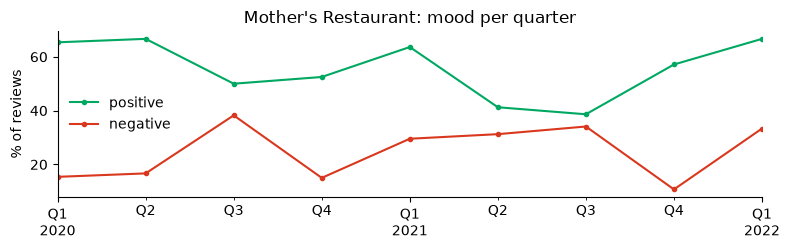

,mentions,posPct,negPct,neuPct,isNew
name,,,,,
Food,681,39.8,19.8,40.4,NaN
New Orleans,130,36.2,3.1,60.8,True
Service,116,54.3,37.1,8.6,NaN
Line,114,13.2,60.5,26.3,True
Ham,106,50.0,17.0,33.0,True
Table,100,8.0,17.0,75.0,NaN
Cheese,89,30.3,11.2,58.4,NaN
Bean,85,30.6,5.9,63.5,True
Drink,84,26.2,21.4,52.4,NaN


Best:  Food, New Orleans, Ham
Worst: Line, Minute, Server


[Output removed before publishing: it shows review text, which the Yelp and Amazon licences don't allow us to republish. Run the notebook locally to see it.]


In [4]:
start = time.time()
rest_in = [{"text": r["text"], "stars": r["stars"], "date": r["date"]} for r in yelp_reviews]
rest_report = analyze_reviews(rest_in, "restaurant", sentiment=sentiment, absa=absa, embed=embed, nlp=nlp)
print(f"analysed in {time.time() - start:,.0f} s")
rest = show_report(shop_name, rest_in, rest_report)

### Reviews with their causes highlighted

The highlights are exact spans of the customer's text: green is a positive cause, red negative, yellow neutral. Hover over one to see its aspect.

In [5]:
show_reviews(rest_in, rest)

[Output removed before publishing: it shows review text, which the Yelp and Amazon licences don't allow us to republish. Run the notebook locally to see it.]


## 3. An appliance product

Appliance product B08888J5W1 · 391 reviews · positive 56.0% · negative 33.5% · average ★ 3.44 · skipped {'nonEnglish': 9, 'empty': 0}


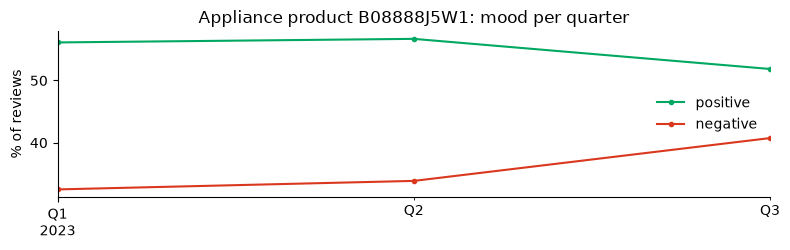

,mentions,posPct,negPct,neuPct,isNew
name,,,,,
Coffee,362,24.3,26.2,49.4,NaN
Cup,170,23.5,22.4,54.1,NaN
Pod,64,26.6,31.2,42.2,True
Filter,60,26.7,28.3,45.0,NaN
Keurig Machine,59,11.9,25.4,62.7,True
Money,51,60.8,31.4,7.8,True
Work,32,65.6,15.6,18.8,NaN
Machine,27,14.8,70.4,14.8,NaN
Bottom,27,18.5,48.1,33.3,True


Best:  Price, Work, Money
Worst: Machine, Lid, Top


[Output removed before publishing: it shows review text, which the Yelp and Amazon licences don't allow us to republish. Run the notebook locally to see it.]


In [6]:
test_app = df[(df["split"] == "test") & (df["domain"] == "appliances")]
product_id = test_app["group_id"].value_counts().index[0]
path = config.RAW_DIR / "amazon" / "raw" / "review_categories" / "Appliances.jsonl"
app_reviews = sorted((r for r in iter_amazon("appliances", read_lines(path)) if r["group_id"] == product_id), key=lambda r: r["date"])[-MAX_REVIEWS:]
app_in = [{"text": r["text"], "stars": r["stars"], "date": r["date"]} for r in app_reviews]
app_report = analyze_reviews(app_in, "electronics", sentiment=sentiment, absa=absa, embed=embed, nlp=nlp)
app = show_report(f"Appliance product {product_id}", app_in, app_report)
show_reviews(app_in, app, n=5)

## 4. A tiny CSV: five reviews, no stars, no dates

Small shops and messy uploads must still work. A shop with almost no history should still get a report, without crashing and without inventing trends.

In [7]:
tiny = [
    {"text": "Lovely haircut and the stylist was so friendly. Booking online was easy.", "stars": None, "date": None},
    {"text": "Waited 40 minutes past my appointment. The stylist was rushed.", "stars": None, "date": None},
    {"text": "Great colour, fair price, but parking was impossible.", "stars": None, "date": None},
    {"text": "Parking is a nightmare here, and the price went up again.", "stars": None, "date": None},
    {"text": "Friendly staff, clean salon, but the parking lot is always full.", "stars": None, "date": None},
]
tiny_report = analyze_reviews(tiny, "salon", sentiment=sentiment, absa=absa, embed=embed, nlp=nlp)
t = show_report("Small salon (CSV)", tiny, tiny_report)
show_reviews(tiny, t, n=5)

Small salon (CSV) · 5 reviews · positive 20.0% · negative 40.0% · average ★ None · skipped {'nonEnglish': 0, 'empty': 0}


,mentions,posPct,negPct,neuPct,isNew
name,,,,,
Parking,3,0.0,100.0,0.0,True
Price,2,50.0,50.0,0.0,NaN
Staff,1,100.0,0.0,0.0,NaN


Best:  –
Worst: Parking


,aspect,tone,reason,reviews,example
0,Parking,negative,always full,1,the parking lot is always full
1,Parking,negative,impossible,1,parking was impossible


## 5. Save the restaurant report

The report is saved as JSON in exactly the shape the app reads, ready for Part 3 to load into the database.

In [8]:
out = config.PROCESSED_DIR / "demo_restaurant_report.json"
out.parent.mkdir(parents=True, exist_ok=True)
out.write_text(json.dumps({"shop": shop_name, "model": model_name, **rest}, indent=1), encoding="utf-8")
print("saved", out.relative_to(config.REPO_ROOT), f"({out.stat().st_size / 1024:,.0f} KB)")

saved data\processed\demo_restaurant_report.json (1,108 KB)


## Key findings

1. **One function gives the whole report, for any shop size.** Mother's Restaurant (400 reviews), a coffee-pod product (391 reviews, 9 skipped as non-English) and a 5-review salon CSV with no stars or dates all produced a report without errors. Per-review sentiment now comes from **DistilBERT** (notebook 03).
2. **The restaurant's story is clear and plausible.** 53.8% positive, 24.0% negative, 3.62★. Worst: **Line** (114 mentions, 60% negative), **Minute** (the wait: reviewers counting the minutes before they reach the cashier) and **Server**. Best: **Food**, **New Orleans** (the tourist pull) and **Ham** (its famous baked ham). A real owner could act on that.
3. **Ranking by net mentions fixed the first run's nonsense.** Ranking by percentage alone had made 9-mention themes like *Hype*, *Issue* and *Glad* the "worst" and "best". Net mentions (positive minus negative) weigh how often *and* how strongly, so the 114-mention Line comes first. The cost: small, sharp problems drop out of the top 3. The pod product's *Error Message* and *Needle* (both real faults, 7–11 negative mentions) now sit below Machine, Lid and Top, though they still appear in the full aspect table.
4. **Reasons now say *why*, not just *what*.** The first runs' reasons mostly repeated the aspect's name (Line → "line", Lid → "lid"), because that word is in nearly every cause. Leaving out each aspect's own words gives Line → **long**, **wait**; Minute → **waited**, **later**; Lid → **close**, **hard close**; Money → **save**; Ham → **famous**. Some are still generic ("good", "great" for Food), and plurals can repeat ("save", "saves"). Counts are now *reviews*, each counted once.
5. **The product's worsts describe one problem from three sides.** Machine, Lid and Top all come from reviews saying the machine's lid won't close with the pod in, and that coffee comes back out over the top: the pods don't fit some Keurig models. A later step could merge aspects that share their quotes.
6. **Remaining weaknesses, all visible above:**
   - **Near-duplicates:** *Line* and *Minute* are both about waiting, and *Server* is separate from Staff.
   - **Place names as themes:** *New Orleans* is a new theme for the restaurant, but it isn't something the shop can change.
   - **Some aspect verdicts are wrong:** a reviewer pleased that a server quickly collects the receipt was counted as negative for Server. That fits notebook 04's ~72% agreement.
   - **The general catalogue misses salon words:** *stylist*, *haircut* and *appointment* matched nothing, so the salon's "Waited 40 minutes past my appointment" has no aspect. Shop types we have no data for will get thinner reports until a salon catalogue exists.
7. **Speed: 189 s for 400 reviews on the laptop CPU** (about 0.5 s per review, mostly the aspect-sentiment model). A CSV upload of a few thousand reviews needs the GPU service (Part 3), not the laptop.
8. **Saved:** `data/processed/demo_restaurant_report.json` (1107 KB) is in the shape the app reads, ready for Part 3's database. It stays out of git because it holds review text.